# Final AR tuning — mean and maximum process-level wins

This notebook compares random and $e_1$ starting directions with absolute and
diameter-normalized initial steps on Jones-sampled AR(3) processes. The process
and realization counts are editable in the experiment settings. Run the cells
from top to bottom. [Experiment runner](../ar_tools/tuning.py).

For each process and configuration, compute both the **mean** and the
**maximum** achieved minimum width across the same realizations. Lower values
are better for either criterion. Compare each criterion across all four grids
independently, award full credit to co-winners, then count process wins.

Each matrix cell shows **Mean** and **Max** process-win counts. The blue shading
uses the mean counts. **Red boxes** mark all highest-count configurations for
the mean criterion; **yellow boxes** mark all highest-count configurations for
the maximum criterion. Inset boxes keep both visible when the leaders coincide.
Grey boxes retain the positive mean-count leaders within each panel.

### Figure exports

The matrix figure is displayed and saved automatically as **PDF and PNG** under
`../outputs/pdfs/ar_tuning_experiments/hierarchical_process_wins_<run-id>/`
and the corresponding `../outputs/images/` folder. No tables or text logs are
displayed; calculation errors still propagate.

Only the PDF and PNG figures are written to disk. Numerical summaries and
rankings remain in memory while the notebook kernel is running.


## 1. Setup


In [64]:
import hashlib
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.utils.capture import capture_output

AR_CODE_DIR = next(
    candidate.resolve()
    for root in (Path.cwd(), *Path.cwd().parents)
    for candidate in (root / "Code" / "Code_AR_processes", root)
    if (candidate / "ar_tools/functions.py").is_file()
)
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Refresh the optimizer as well as the tuner in an existing notebook kernel.
from Code.Code_AR_processes.ar_tools import descent as descent_tools
descent_tools = importlib.reload(descent_tools)
# Refresh the local tuning helpers when setup is rerun in an existing kernel.
from Code.Code_AR_processes.ar_tools import tuning as tuning_tools
tuning_tools = importlib.reload(tuning_tools)
from Code.Code_AR_processes.ar_tools.functions import jones_ar_coefficients
with plt.rc_context():
    from Code.Code_AR_processes.ar_tools.plotting_functions import save_figure

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"font.size": 10, "pdf.fonttype": 42})
EXPERIMENT_NAME = "ar_tuning_experiments"
OUTPUT_ROOT = AR_CODE_DIR / "outputs"


### Optimizer settings and tuning grids

The grid is $H\in\{2,5,10,20,50,100,200,1000\}$ and
$c\in\{0.1,0.2,\ldots,0.9\}$, with $\beta=2^{-1/H}$.
Each scale gives $\gamma_0=c$ for absolute steps or $\gamma_0=c/L$ for
diameter-normalized steps, where $L$ is the empirical point-cloud diameter.
There are 72 configurations per start/step variant and 288 in total.
[Grid and step rules](../ar_tools/tuning.py).

The experiment uses a **2,000-iteration cap and patience 200**.
`improvement_tolerance=0` records every strictly smaller width. The separate
**`delta=1e-8`** resets patience only after a cumulative decrease of at least
`delta` from the previous patience reference; that reference then becomes the
current best width. Stop after 200 consecutive iterations without such a
decrease, or at the iteration cap. Set `delta=0` to reset patience after every
strict improvement. Each descent uses one start, with stationarity checks and
restarts disabled. [Stopping implementation](../ar_tools/descent.py).

Each path has $T=500$ retained observations and uniform innovations on $[-1,1]$,
after 2,000 discarded burn-in observations. Seeds and burn-in are explicit
experimental settings. The process-win tolerance is configured separately in
Section 2 for each criterion and applies **after taking the mean or maximum
within each process**.
[Simulation](../ar_tools/functions.py), [paired runner](../ar_tools/tuning.py).


In [65]:
T = 500
p = 3
burnin = 2_000
optimizer_seed = 20261019
embedding_dimension = p + 1

max_iterations = 2_000
patience = 200
improvement_tolerance = 0.0  # Retain every strictly smaller width.
delta = 1e-8  # Cumulative width decrease required to reset patience.
scale_grid = np.arange(1, 10) / 10.0  # 0.1, 0.2, ..., 0.9
half_life_grid = np.array([2, 5, 10, 20, 50, 100, 200, 1000])

if p != 3 or embedding_dimension != 4:
    raise ValueError("This experiment requires an AR(3) model and four-coordinate windows.")
if T < embedding_dimension + 1 or burnin < 0:
    raise ValueError("Use enough observations to form at least two windows and nonnegative burn-in.")
if (isinstance(delta, (bool, np.bool_))
        or not isinstance(delta, (int, float, np.integer, np.floating))
        or not np.isfinite(delta) or delta < 0):
    raise ValueError("delta must be a finite nonnegative number.")


## 2. Final tuning: mean and maximum criteria

For each Jones-sampled causal AR(3) coefficient vector, generate the configured
number of independent innovation paths. All configurations and all four
start/step variants use the same paths. Draw a random-start bank once; reuse
direction r for realization r of every process and every random-start
configuration. Coefficient draws, innovations and starting directions have
separate seeded streams. The $e_1$ variants always start at $e_1$.
[Sampler](../ar_tools/functions.py), [paired fixed-process runner](../ar_tools/tuning.py).

For each process and configuration, summarize the achieved minimum widths over
realizations in two ways:

- **Mean:** average the achieved widths, then compare all four grids together.
  Every configuration within `hierarchical_mean_win_tolerance` of the lowest
  mean receives one mean-process win.
- **Maximum:** take the largest achieved width among that process's simulated
  realizations, then compare all four grids together. Every configuration within
  `hierarchical_max_win_tolerance` of the **smallest maximum** receives one
  max-process win. This summarizes the worst observed realization in the run.

Both tolerances default to $10^{-8}$ and comparisons use unrounded values.
The two criteria are evaluated independently on the same fits. Full credit is
awarded to ties. Final counts range from zero to the number of processes;
total credits can exceed that number. Each criterion selects every configuration
tied for its highest process-win count. With one realization, mean and maximum
scores and wins coincide when their tolerances match.

The four matrix panels show both counts. Blue shading and red boxes use the
mean criterion; yellow boxes identify the overall max-criterion leaders. Grey
boxes mark each panel's highest positive mean count, using the same global
contest. Zero-mean-count panels are labelled and receive no grey box. When
boxes share a cell, they are inset so all remain visible. No MAE or iteration
annotations are displayed.

Run the setup cells above, then every cell in this section. Individual fits
are summarized one process at a time. The per-process means, maxima, co-winners
and final rankings remain in memory; only the matrix figure is saved as PDF/PNG.
The process and realization counts remain editable below.


In [66]:
# Run the setup cells above before these experiment cells.
hierarchical_number_of_processes = 100
hierarchical_realizations_per_process = 100
hierarchical_coefficient_seed = 20261029
hierarchical_innovation_seed = 20261030
hierarchical_direction_seed = 20261031
hierarchical_mean_win_tolerance = 1e-8  # Applied to per-process means.
hierarchical_max_win_tolerance = 1e-8  # Applied to per-process maxima; smaller is better.
hierarchical_n_jobs = 4  # Parallel realization workers within one process.


In [67]:
for hierarchical_value, hierarchical_name in (
    (hierarchical_number_of_processes, "number of processes"),
    (hierarchical_realizations_per_process, "realizations per process"),
    (hierarchical_n_jobs, "workers"),
):
    if (isinstance(hierarchical_value, (bool, np.bool_))
            or not isinstance(hierarchical_value, (int, np.integer)) or hierarchical_value < 1):
        raise ValueError(f"The {hierarchical_name} must be a positive integer.")
for hierarchical_tolerance, hierarchical_name in (
    (hierarchical_mean_win_tolerance, "mean-width"),
    (hierarchical_max_win_tolerance, "maximum-width"),
):
    if (not np.isfinite(hierarchical_tolerance) or hierarchical_tolerance < 0):
        raise ValueError(f"The {hierarchical_name} tolerance must be finite and nonnegative.")

# Draw this bank once. Row r is reused for realization r of EVERY process.
hierarchical_start_bank = np.random.default_rng(hierarchical_direction_seed).normal(
    size=(hierarchical_realizations_per_process, embedding_dimension),
)
hierarchical_start_bank /= np.linalg.norm(hierarchical_start_bank, axis=1, keepdims=True)
hierarchical_e1 = np.zeros(embedding_dimension)
hierarchical_e1[0] = 1.
hierarchical_start_columns = [f"initial_u_{j}" for j in range(embedding_dimension)]

# Each process receives distinct coefficient and innovation streams.
# The fixed-process runner then spawns one innovation seed per realization.
hierarchical_coefficient_streams = np.random.SeedSequence(hierarchical_coefficient_seed).spawn(
    hierarchical_number_of_processes,
)
hierarchical_innovation_streams = np.random.SeedSequence(hierarchical_innovation_seed).spawn(
    hierarchical_number_of_processes,
)
hierarchical_models = pd.DataFrame([
    {
        "model_id": index + 1,
        "coefficient_seed": int(coefficient_stream.generate_state(1, dtype=np.uint64)[0]),
        "innovation_root_seed": int(innovation_stream.generate_state(1, dtype=np.uint64)[0]),
    }
    for index, (coefficient_stream, innovation_stream) in enumerate(zip(
        hierarchical_coefficient_streams, hierarchical_innovation_streams,
    ))
])
hierarchical_coefficients = np.stack([
    jones_ar_coefficients(p, rng=int(seed)) for seed in hierarchical_models["coefficient_seed"]
])
for hierarchical_j in range(p):
    hierarchical_models[f"phi_{hierarchical_j+1}"] = hierarchical_coefficients[:, hierarchical_j]
assert hierarchical_models["coefficient_seed"].is_unique
assert hierarchical_models["innovation_root_seed"].is_unique
assert np.unique(hierarchical_coefficients, axis=0).shape[0] == hierarchical_number_of_processes
hierarchical_grid_size = len(scale_grid) * len(half_life_grid)
hierarchical_total_descents = (
    hierarchical_number_of_processes * hierarchical_realizations_per_process * 4 * hierarchical_grid_size
)
hierarchical_configuration = {
    "experiment": "process_wins_from_mean_and_max_achieved_width", "processes": hierarchical_number_of_processes,
    "realizations_per_process": hierarchical_realizations_per_process,
    "total_descents": int(hierarchical_total_descents),
    "coefficient_seed": hierarchical_coefficient_seed, "innovation_seed": hierarchical_innovation_seed,
    "direction_seed": hierarchical_direction_seed, "start_bank": hierarchical_start_bank.tolist(),
    "random_starts": "same_realization_index_reused_across_all_processes",
    "T": int(T), "p": int(p), "burnin": int(burnin), "optimizer_seed": int(optimizer_seed),
    "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
    "beta_grid": np.exp2(-1. / half_life_grid).tolist(),
    "iterations": int(max_iterations), "patience": int(patience), "delta": float(delta),
    "improvement_tolerance": float(improvement_tolerance),
    "mean_win_tolerance": float(hierarchical_mean_win_tolerance),
    "max_win_tolerance": float(hierarchical_max_win_tolerance),
    "starts": 1, "stationarity_check": False, "max_restarts": 0,
    "source_sha256": hashlib.sha256(b"".join(
        (AR_CODE_DIR / "ar_tools" / name).read_bytes()
        for name in ("functions.py", "innovations.py", "descent.py", "tuning.py")
    )).hexdigest(),
}
hierarchical_run_id = hashlib.sha256(repr(sorted(hierarchical_configuration.items())).encode()).hexdigest()[:16]
HIERARCHICAL_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"hierarchical_process_wins_{hierarchical_run_id}"
HIERARCHICAL_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"hierarchical_process_wins_{hierarchical_run_id}"
for hierarchical_directory in (HIERARCHICAL_PDF_DIR, HIERARCHICAL_IMAGE_DIR):
    hierarchical_directory.mkdir(parents=True, exist_ok=True)


In [68]:
def summarize_process_widths(runs, model_id):
    """Compute independent mean/minimax co-winners on the same realized fits."""
    if not np.isfinite(runs["minimum_width"]).all():
        raise ValueError("All achieved widths must be finite; failed fits cannot be omitted.")
    summaries = runs.groupby(
        ["initialization", "step_rule", "candidate_id", "step_value", "half_life", "beta"],
        as_index=False,
    ).agg(
        mean_achieved_width=("minimum_width", "mean"),
        max_achieved_width=("minimum_width", "max"),
        realization_count=("replication", "size"),
    )
    assert len(summaries) == 4 * hierarchical_grid_size
    assert summaries["realization_count"].eq(hierarchical_realizations_per_process).all()
    best_mean = summaries["mean_achieved_width"].min()
    best_max = summaries["max_achieved_width"].min()
    return summaries.assign(
        model_id=model_id, process_best_mean=best_mean, process_best_max=best_max,
        process_win=summaries["mean_achieved_width"].le(best_mean + hierarchical_mean_win_tolerance),
        max_process_win=summaries["max_achieved_width"].le(best_max + hierarchical_max_win_tolerance),
    )


In [69]:
def hierarchical_tune_one_process(model_id, phi, innovation_root_seed):
    """Summarize realized widths by mean and maximum, then award independent wins."""
    frames = []
    reference_cases = None
    pairing_columns = [
        "replication", "T", "process_seed", "phi_1", "phi_2", "phi_3",
        "population_minimum_width", "empirical_true_direction_width",
    ]
    for initialization, directions in (
        ("random_shared_bank", hierarchical_start_bank), ("e1", hierarchical_e1),
    ):
        for step_rule in ("absolute", "diameter_normalized"):
            experiment = tuning_tools.tune_fixed_ar_realizations(
                phi, T, directions, scale_grid, half_life_grid,
                replications=hierarchical_realizations_per_process,
                process_seed=innovation_root_seed, burnin=burnin,
                iterations=max_iterations, patience=patience,
                improvement_tolerance=improvement_tolerance, delta=delta,
                optimizer_seed=optimizer_seed, step_rule=step_rule,
                stationarity_check=False, max_restarts=0, coefficient_diagnostics=False,
                n_jobs=hierarchical_n_jobs, progress=False, summarize=False,
            )
            cases = pd.DataFrame(experiment["cases"]).sort_values("replication").reset_index(drop=True)
            assert len(cases) == hierarchical_realizations_per_process
            assert cases["process_seed"].is_unique
            if reference_cases is None:
                reference_cases = cases.copy()
            pd.testing.assert_frame_equal(cases[pairing_columns], reference_cases[pairing_columns], check_exact=True)
            expected_starts = (hierarchical_start_bank if initialization == "random_shared_bank"
                               else np.tile(hierarchical_e1, (hierarchical_realizations_per_process, 1)))
            np.testing.assert_allclose(cases[hierarchical_start_columns], expected_starts, atol=1e-15, rtol=0)
            runs = pd.DataFrame(experiment["results"]).assign(initialization=initialization)
            assert len(runs) == hierarchical_realizations_per_process * hierarchical_grid_size
            assert not runs.duplicated(["candidate_id", "replication"]).any()
            assert np.isfinite(runs["minimum_width"]).all()  # Do not silently omit failed runs.
            assert runs["selected_start"].eq(1).all()
            assert runs["total_evaluations"].between(1, max_iterations).all()
            np.testing.assert_array_equal(runs[["phi_1", "phi_2", "phi_3"]], np.tile(phi, (len(runs), 1)))
            np.testing.assert_array_equal(
                runs[hierarchical_start_columns].to_numpy(),
                cases.set_index("replication").loc[runs["replication"], hierarchical_start_columns].to_numpy(),
            )
            frames.append(runs)
    all_runs = pd.concat(frames, ignore_index=True)
    means = summarize_process_widths(all_runs, model_id)
    # Keep only per-process summaries and seed/start records in memory.
    seed_records = reference_cases[pairing_columns + hierarchical_start_columns].assign(model_id=model_id)
    return means, seed_records

with capture_output():
    hierarchical_mean_frames = []
    hierarchical_seed_frames = []
    for hierarchical_model in hierarchical_models.itertuples(index=False):
        hierarchical_phi = np.array([
            getattr(hierarchical_model, f"phi_{j+1}") for j in range(p)
        ])
        hierarchical_means, hierarchical_seeds = hierarchical_tune_one_process(
            int(hierarchical_model.model_id), hierarchical_phi,
            int(hierarchical_model.innovation_root_seed),
        )
        hierarchical_mean_frames.append(hierarchical_means)
        hierarchical_seed_frames.append(hierarchical_seeds)
    hierarchical_process_means = pd.concat(hierarchical_mean_frames, ignore_index=True)
    hierarchical_realization_metadata = pd.concat(hierarchical_seed_frames, ignore_index=True)
    assert hierarchical_realization_metadata["process_seed"].is_unique
    assert not hierarchical_process_means.duplicated(["model_id", "initialization", "candidate_id"]).any()


In [70]:
with capture_output():
    hierarchical_ranking = hierarchical_process_means.groupby(
        ["initialization", "step_rule", "candidate_id", "step_value", "half_life", "beta"], as_index=False,
    ).agg(
        process_wins=("process_win", "sum"),
        max_process_wins=("max_process_win", "sum"),
        process_count=("model_id", "nunique"),
    )
    for hierarchical_count_column in ("process_wins", "max_process_wins"):
        hierarchical_ranking[hierarchical_count_column] = hierarchical_ranking[hierarchical_count_column].astype(int)
    hierarchical_ranking = hierarchical_ranking.sort_values(
        ["process_wins", "initialization", "step_rule", "step_value", "half_life"],
        ascending=[False, True, True, True, True],
    ).reset_index(drop=True)
    assert hierarchical_ranking["process_count"].eq(hierarchical_number_of_processes).all()
    assert hierarchical_ranking["process_wins"].between(0, hierarchical_number_of_processes).all()
    assert hierarchical_ranking["process_wins"].sum() == hierarchical_process_means["process_win"].sum()
    assert hierarchical_process_means.groupby("model_id")["process_win"].any().all()
    assert hierarchical_ranking["max_process_wins"].between(0, hierarchical_number_of_processes).all()
    assert hierarchical_ranking["max_process_wins"].sum() == hierarchical_process_means["max_process_win"].sum()
    assert hierarchical_process_means.groupby("model_id")["max_process_win"].any().all()
    hierarchical_max_ranking = hierarchical_ranking.sort_values(
        ["max_process_wins", "initialization", "step_rule", "step_value", "half_life"],
        ascending=[False, True, True, True, True],
    ).reset_index(drop=True)
    hierarchical_max_best_count = int(hierarchical_max_ranking["max_process_wins"].max())
    hierarchical_max_leaders = hierarchical_max_ranking.loc[
        hierarchical_max_ranking["max_process_wins"].eq(hierarchical_max_best_count)
    ].copy()
    hierarchical_best_count = int(hierarchical_ranking["process_wins"].max())
    hierarchical_leaders = hierarchical_ranking.loc[
        hierarchical_ranking["process_wins"].eq(hierarchical_best_count)
    ].copy()


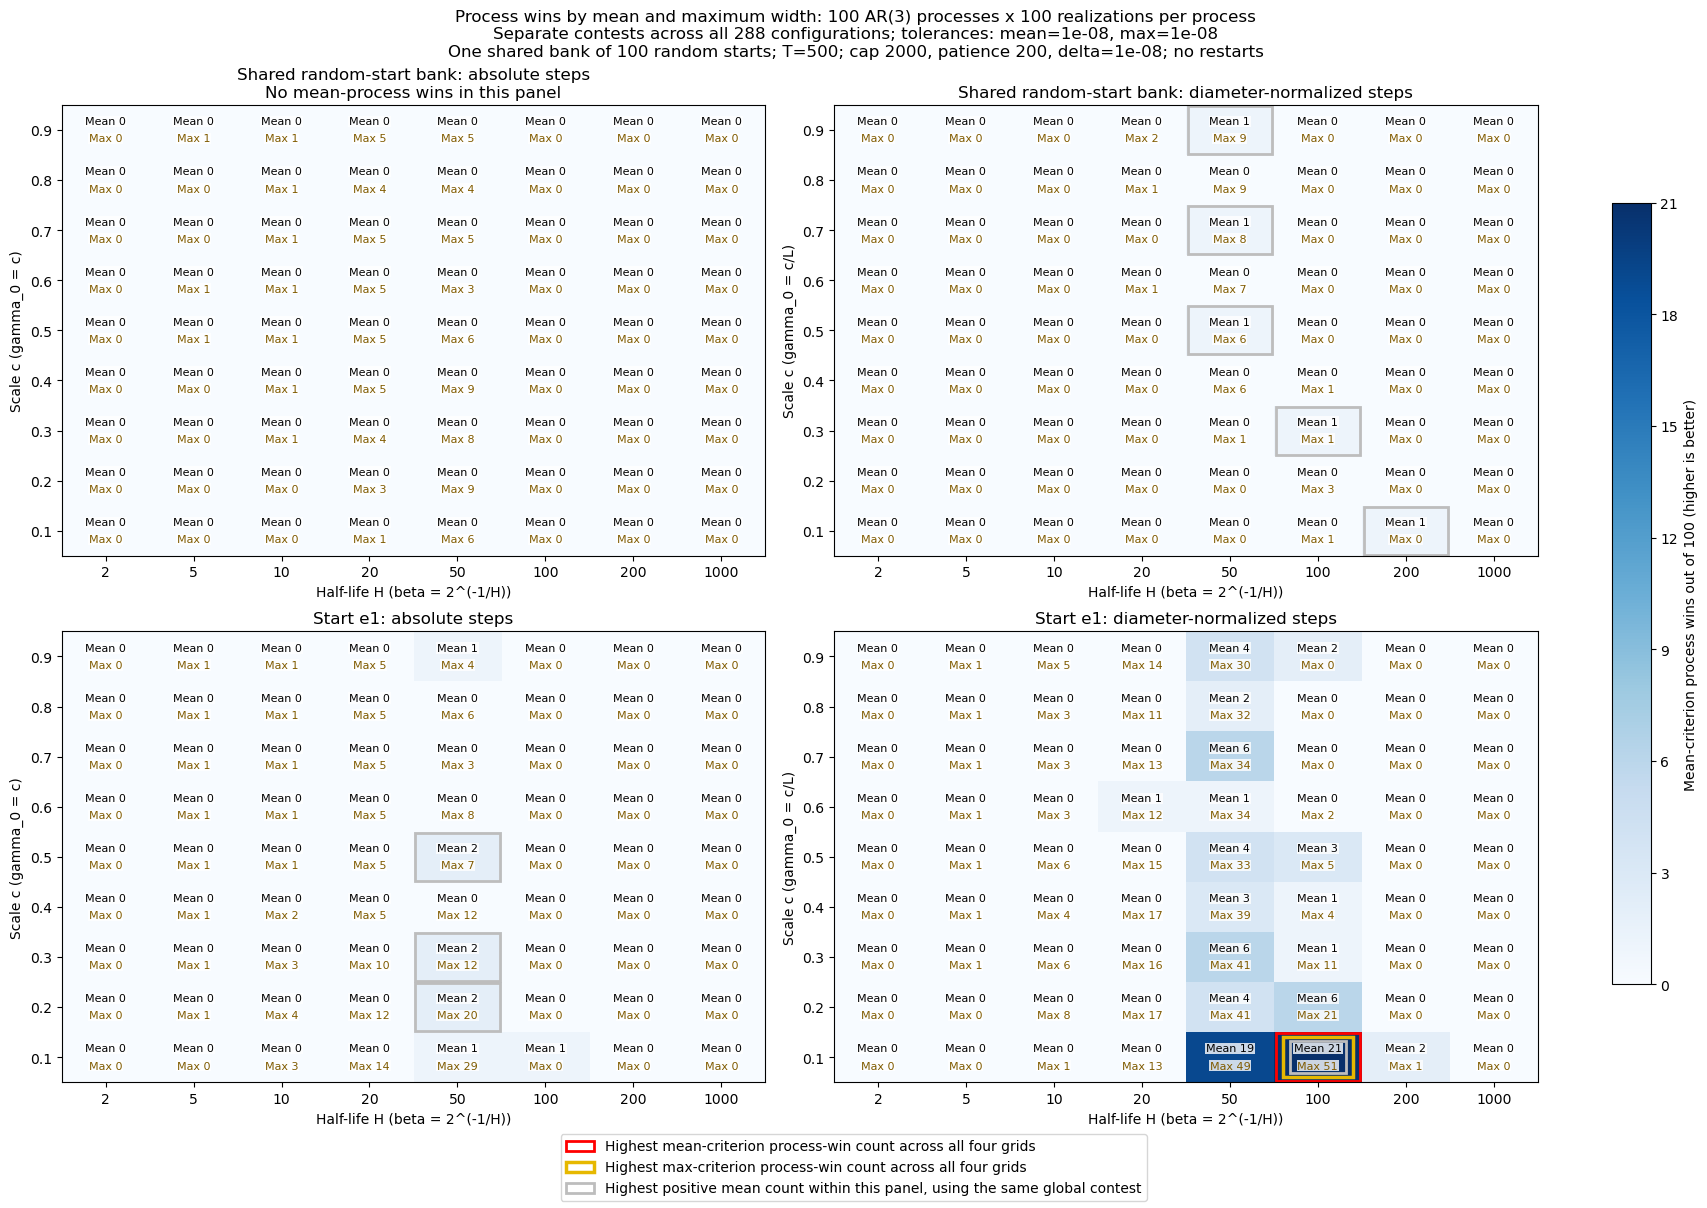

In [71]:
hierarchical_fig, hierarchical_axes = plt.subplots(2, 2, figsize=(17, 12), constrained_layout=True)
hierarchical_color_max = max(1, hierarchical_best_count)
hierarchical_grey = "#bdbdbd"
hierarchical_yellow = "#e6b800"
hierarchical_matrices = {}
hierarchical_max_matrices = {}
for hierarchical_row, hierarchical_start in enumerate(("random_shared_bank", "e1")):
    for hierarchical_col, hierarchical_rule in enumerate(("absolute", "diameter_normalized")):
        hierarchical_ax = hierarchical_axes[hierarchical_row, hierarchical_col]
        hierarchical_panel = hierarchical_ranking.loc[
            hierarchical_ranking["initialization"].eq(hierarchical_start)
            & hierarchical_ranking["step_rule"].eq(hierarchical_rule)
        ]
        hierarchical_matrix = hierarchical_panel.pivot(
            index="step_value", columns="half_life", values="process_wins",
        ).reindex(index=scale_grid, columns=half_life_grid)
        hierarchical_max_matrix = hierarchical_panel.pivot(
            index="step_value", columns="half_life", values="max_process_wins",
        ).reindex(index=scale_grid, columns=half_life_grid)
        assert hierarchical_matrix.notna().all().all()
        assert hierarchical_max_matrix.notna().all().all()
        hierarchical_matrices[(hierarchical_start, hierarchical_rule)] = hierarchical_matrix
        hierarchical_max_matrices[(hierarchical_start, hierarchical_rule)] = hierarchical_max_matrix
        hierarchical_panel_best = int(hierarchical_panel["process_wins"].max())
        hierarchical_image = hierarchical_ax.imshow(
            hierarchical_matrix.to_numpy(), origin="lower", aspect="auto", cmap="Blues",
            vmin=0, vmax=hierarchical_color_max,
        )
        for hierarchical_i in range(len(scale_grid)):
            for hierarchical_j in range(len(half_life_grid)):
                hierarchical_count = int(hierarchical_matrix.iloc[hierarchical_i, hierarchical_j])
                hierarchical_max_count = int(hierarchical_max_matrix.iloc[hierarchical_i, hierarchical_j])
                hierarchical_mean_leader = hierarchical_count == hierarchical_best_count
                hierarchical_max_leader = hierarchical_max_count == hierarchical_max_best_count
                for hierarchical_offset, hierarchical_label, hierarchical_text_color in (
                    (.17, f"Mean {hierarchical_count}", "black"),
                    (-.17, f"Max {hierarchical_max_count}", "#805b00"),
                ):
                    hierarchical_ax.text(
                        hierarchical_j, hierarchical_i + hierarchical_offset, hierarchical_label,
                        ha="center", va="center", fontsize=8,
                        color=hierarchical_text_color,
                        bbox={"facecolor":"white", "alpha":.8, "edgecolor":"none", "pad":.5},
                    )
                if hierarchical_panel_best > 0 and hierarchical_count == hierarchical_panel_best:
                    hierarchical_extent = .32 if hierarchical_mean_leader and hierarchical_max_leader else (
                        .40 if hierarchical_mean_leader or hierarchical_max_leader else .48
                    )
                    hierarchical_ax.add_patch(Rectangle(
                        (hierarchical_j-hierarchical_extent, hierarchical_i-hierarchical_extent),
                        2*hierarchical_extent, 2*hierarchical_extent,
                        fill=False, edgecolor=hierarchical_grey, linewidth=2,
                    ))
                if hierarchical_mean_leader:
                    hierarchical_ax.add_patch(Rectangle(
                        (hierarchical_j-.48, hierarchical_i-.48), .96, .96,
                        fill=False, edgecolor="red", linewidth=2,
                    ))
                if hierarchical_max_leader:
                    hierarchical_extent = .40 if hierarchical_mean_leader else .48
                    hierarchical_ax.add_patch(Rectangle(
                        (hierarchical_j-hierarchical_extent, hierarchical_i-hierarchical_extent),
                        2*hierarchical_extent, 2*hierarchical_extent,
                        fill=False, edgecolor=hierarchical_yellow, linewidth=2.5,
                    ))
        hierarchical_start_label = "Shared random-start bank" if hierarchical_start == "random_shared_bank" else "Start e1"
        hierarchical_rule_label = "absolute steps" if hierarchical_rule == "absolute" else "diameter-normalized steps"
        hierarchical_panel_title = f"{hierarchical_start_label}: {hierarchical_rule_label}"
        if hierarchical_panel_best == 0:
            hierarchical_panel_title += "\nNo mean-process wins in this panel"
        hierarchical_ax.set(
            title=hierarchical_panel_title,
            xticks=np.arange(len(half_life_grid)), xticklabels=[f"{h:g}" for h in half_life_grid],
            yticks=np.arange(len(scale_grid)), yticklabels=[f"{c:g}" for c in scale_grid],
            xlabel="Half-life H (beta = 2^(-1/H))",
            ylabel="Scale c (gamma_0 = c)" if hierarchical_rule == "absolute" else "Scale c (gamma_0 = c/L)",
        )
hierarchical_fig.suptitle(
    f"Process wins by mean and maximum width: {hierarchical_number_of_processes} AR(3) processes x "
    f"{hierarchical_realizations_per_process} realizations per process\n"
    f"Separate contests across all {4*hierarchical_grid_size} configurations; "
    f"tolerances: mean={hierarchical_mean_win_tolerance:g}, max={hierarchical_max_win_tolerance:g}\n"
    f"One shared bank of {hierarchical_realizations_per_process} random starts; T={T}; "
    f"cap {max_iterations}, patience {patience}, delta={delta:g}; no restarts",
)
hierarchical_colorbar = hierarchical_fig.colorbar(
    hierarchical_image, ax=hierarchical_axes.ravel().tolist(), shrink=.8,
    label=f"Mean-criterion process wins out of {hierarchical_number_of_processes} (higher is better)",
)
hierarchical_colorbar.set_ticks(np.unique(np.linspace(
    0, hierarchical_color_max, min(hierarchical_color_max+1, 8), dtype=int,
)))
hierarchical_fig.legend(handles=[
    Patch(fill=False, edgecolor="red", linewidth=2, label="Highest mean-criterion process-win count across all four grids"),
    Patch(fill=False, edgecolor=hierarchical_yellow, linewidth=2.5,
          label="Highest max-criterion process-win count across all four grids"),
    Patch(fill=False, edgecolor=hierarchical_grey, linewidth=2,
          label="Highest positive mean count within this panel, using the same global contest"),
], loc="outside lower center", ncol=1)
hierarchical_figure_stem = (
    f"01_hierarchical_{hierarchical_number_of_processes}_processes_"
    f"{hierarchical_realizations_per_process}_realizations_mean_and_max_process_win_counts_2x2"
)
save_figure(hierarchical_fig, hierarchical_figure_stem,
            pdf_directory=HIERARCHICAL_PDF_DIR, image_directory=HIERARCHICAL_IMAGE_DIR)
plt.show()
plt.close(hierarchical_fig)
